# Reasoning under Uncertainty

Logic and Knowledge Graphs enable us to represent statements of fact, but we do not always have complete knowledge of the world and our knowledge is often uncertain. In this section we will develop techniques for representing and reasoning over knowledge that is subject to uncertainty, developing a class of probabilistic models known as Bayesian Networks that will allow us to efficiently make inferences over uncertain knowledge.


## Introduction to Probabilistic Reasoning

Intelligent agents need to be able to handle uncertainty. Their knowledge of the world may be incomplete, or it may be imprecise. The logic-based approaches we have seen in this module can handle incomplete knowledge by returning multiple possible solutions to a problem (no matter how implausible they may be), but they cannot handle imprecise knowledge.

Our principle for describing uncertainty will be the language of **probability**. We will treat the variables that describe our problem as *random variables* with associated probability distributions and we will develop methods for propagating our uncertainty about the inputs of a problem through to the quantities that we wish to predict.

 You may have seen some examples of probabilistic reasoning on other modules on this programme. These problems have typically involved one or two random variables and you have been able to calculate a range of quantities related to the problem using relatively simple calculations. One of the main challenges with probabilistic reasoning is that as the number of random variables increases, the number of parameters increases much faster than the number of variables. Historically this has made large probabilistic reasoning problems computationally intractable. Bayesian networks provide us with a way of dealing with this by allowing us to *factorise* a multivariate joint distribution and thus reduce the number of parameters.

## Recap of definitions from Probability Theory

Let us briefly recall some key ideas and definitions which we will use in this section. These definitions are for discrete probability distributions; similar definitions exist for continuous distributions.

### A running example

To make the definitions concrete, each one below is followed by a worked example based on a simple medical test. Imagine that 100 people are tested for a condition. Let $D$ be the random variable "has the disease" (values $D$ and $\lnot D$) and let $T$ be the test result (values $+$ and $-$). We can picture the 100 people as a $10\times10$ grid of squares, one square per person, coloured by *disease status* (red or blue) and *test result* (dark for positive, light for negative). Counting the squares of each colour gives the table of *joint probabilities*, each square being worth $1/100=0.01$:

| | $T=+$ | $T=-$ |
|:--|:-:|:-:|
| $D$ | 0.08 (8 squares) | 0.02 (2 squares) |
| $\lnot D$ | 0.09 (9 squares) | 0.81 (81 squares) |

The figure below shows the grid and how each of the definitions that follow corresponds to counting, or restricting attention to, a particular set of squares.

![The probability grid: a 10x10 grid of squares showing the joint, marginal and conditional distributions and independence for a medical test.](./figures/probability_grid.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Naming convention: P(A) -> PA, P(A|B) -> PA_B, P(A,B|C,D) -> PAB_CD.
# Arrays are indexed in the same order as the name, e.g. PA_BC[ia][ib][ic],
# and the value of a variable increases with its index.
#
# Joint distribution P(D,T) of disease D and test result T, stored as PDT[d][t]
#   d: 0 = no disease, 1 = disease
#   t: 0 = test negative, 1 = test positive
PDT = np.array([[0.81, 0.09],
                [0.02, 0.08]])
print(PDT)
print("Number of squares of each type out of 100:")
print(np.round(100*PDT).astype(int))

[[0.81 0.09]
 [0.02 0.08]]
Number of squares of each type out of 100:
[[81  9]
 [ 2  8]]


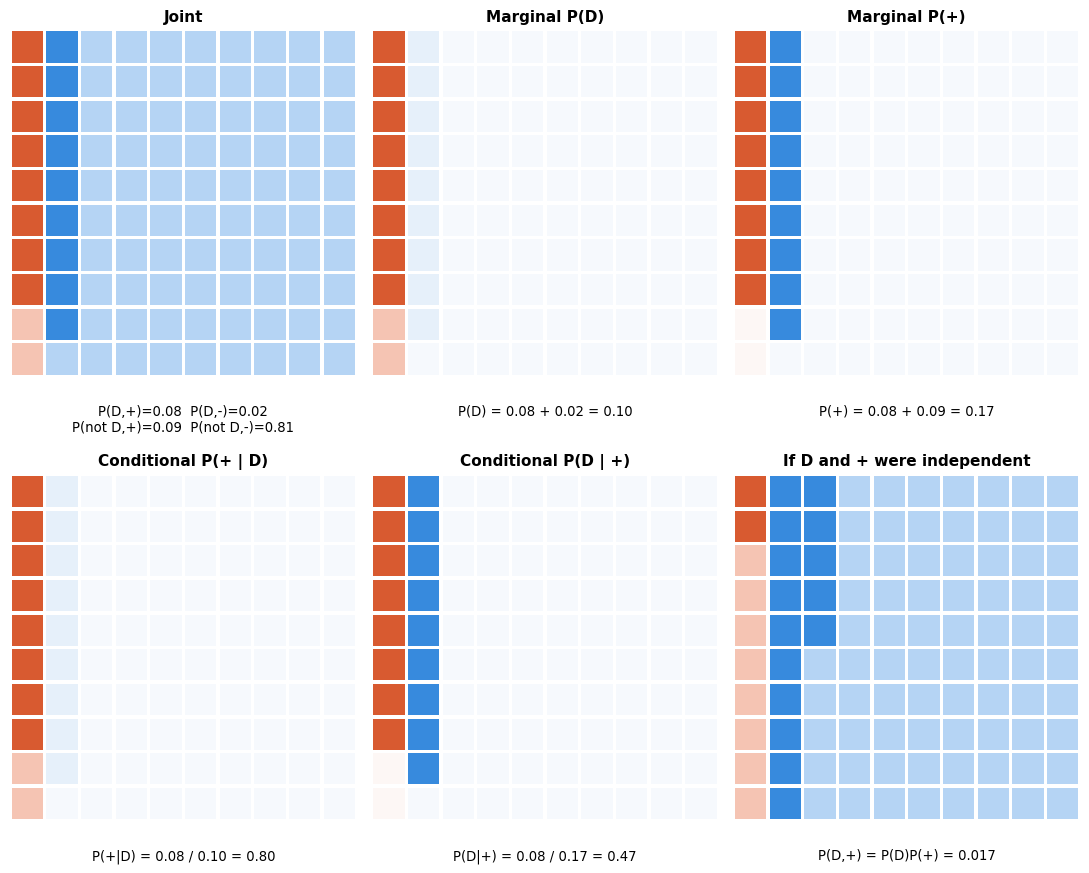

In [2]:
# Code to draw the grid figure above. Each panel colours the 100 squares by (disease, test result)
# and fades the squares that are not part of the quantity being illustrated.
colours = {(1,1): '#D85A30', (1,0): '#F5C4B3', (0,1): '#378ADD', (0,0): '#B5D4F4'}

def draw_grid(ax, counts, faded, title, text):
    """counts[(d,t)] = number of squares; faded(d,t) -> True if the square should be faded"""
    squares = []
    for key in [(1,1), (1,0), (0,1), (0,0)]:
        squares += [key]*counts[key]
    for n, (d, t) in enumerate(squares):
        col, row = divmod(n, 10)
        ax.add_patch(plt.Rectangle((col+0.05, 9-row+0.05), 0.9, 0.9, fc=colours[(d,t)],
                                   ec='none', alpha=0.12 if faded(d,t) else 1))
    ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.text(5, -0.8, text, ha='center', va='top', fontsize=9.5)

counts = {(d,t): int(round(100*PDT[d,t])) for d in (0,1) for t in (0,1)}
# Counts if D and T were independent: 100 * P(D) * P(T), rounded to whole squares
PD = PDT.sum(axis=1); PT = PDT.sum(axis=0)
indep_counts = {(d,t): int(round(100*PD[d]*PT[t])) for d in (0,1) for t in (0,1)}

fig, axs = plt.subplots(2, 3, figsize=(11, 9))
draw_grid(axs[0,0], counts, lambda d,t: False, 'Joint', 'P(D,+)=0.08  P(D,-)=0.02\nP(not D,+)=0.09  P(not D,-)=0.81')
draw_grid(axs[0,1], counts, lambda d,t: d==0, 'Marginal P(D)', 'P(D) = 0.08 + 0.02 = 0.10')
draw_grid(axs[0,2], counts, lambda d,t: t==0, 'Marginal P(+)', 'P(+) = 0.08 + 0.09 = 0.17')
draw_grid(axs[1,0], counts, lambda d,t: d==0, 'Conditional P(+ | D)', 'P(+|D) = 0.08 / 0.10 = 0.80')
draw_grid(axs[1,1], counts, lambda d,t: t==0, 'Conditional P(D | +)', 'P(D|+) = 0.08 / 0.17 = 0.47')
draw_grid(axs[1,2], indep_counts, lambda d,t: False, 'If D and + were independent', 'P(D,+) = P(D)P(+) = 0.017')
plt.tight_layout()
plt.show()

### The Joint Distribution

The joint distribution of random variables $X_1, X_2,\dots, X_N$ is written as 

$P(\mathbf{X}) = P(X_1, X_2,\dots, X_N)$

With this notation, the probability that $(X_1=x_1) \land (X_2=y_2) \land \dots\land (X_N=x_N)$ is

$P(\mathbf{X=\mathbf{x}}) = P(X_1=x_1, X_2=x_2,\dots, X_N=x_n)$.

**Example.** In the grid, $P(D,T=+)$ is the probability of a person who has the disease *and* tests positive. There are 8 such squares out of 100, so $P(D,T=+)=0.08$. The four joint probabilities in the table are non-negative and sum to one, $0.08+0.02+0.09+0.81=1$. Two binary variables need $2^2-1=3$ free parameters to specify their joint distribution.

In [3]:
# P(D, T=+): the entry for disease and positive test
print("P(D, T=+) =", PDT[1, 1])

# The joint probabilities are non-negative and sum to one
print("Sum of joint probabilities =", round(PDT.sum(), 10))

# Free parameters needed for the joint distribution of N binary variables: 2**N - 1
N = 2
print("Free parameters for two binary variables:", 2**N - 1)

P(D, T=+) = 0.08
Sum of joint probabilities = 1.0
Free parameters for two binary variables: 3


### Marginalisation and the Sum Rule

If we wish to know the overall distribution of a subset of the random variables, we *marginalise* over the other variables. For example:

$P(X_j, X_k) = \sum_{x_i:\, i\neq j,k} P(X_1=x_1, X_2=x_2,\dots,X_N=x_N)$

where the sum is over all possible values of each of the variables other than $X_j$ and $X_k$.

**Example.** To find the overall probability of having the disease, ignoring the test, we sum over the possible test results:

$$P(D)=\sum_{t}P(D,T=t)=P(D,+)+P(D,-)=0.08+0.02=0.10$$

and similarly $P(\lnot D)=0.09+0.81=0.90$. To find the overall probability of testing positive, ignoring the disease status, we sum over the disease:

$$P(T=+)=\sum_{d}P(D=d,T=+)=P(D,+)+P(\lnot D,+)=0.08+0.09=0.17$$

and $P(T=-)=0.02+0.81=0.83$. In the grid, marginalising means counting squares of one hue regardless of shade (for $P(D)$), or counting all the dark squares regardless of hue (for $P(T=+)$).

In [4]:
# Marginalise by summing over the axis of the variable we want to remove
PD = PDT.sum(axis=1)   # sum over T (axis 1)  -> P(D),  index 0: no disease, 1: disease
PT = PDT.sum(axis=0)   # sum over D (axis 0)  -> P(T),  index 0: negative,   1: positive

print("P(D=no), P(D=yes) =", np.round(PD, 4))
print("P(T=-),  P(T=+)   =", np.round(PT, 4))

# The same thing written as an explicit sum for P(D)
print("P(D) = P(D,+) + P(D,-) =", PDT[1, 1] + PDT[1, 0])

P(D=no), P(D=yes) = [0.9 0.1]
P(T=-),  P(T=+)   = [0.83 0.17]
P(D) = P(D,+) + P(D,-) = 0.1


### Conditional Probability

If we wish to know the distribution of a subset of the random variables at a *fixed value* of the other random variables, we compute the *conditional* probability as (for a two-variable example)

$P(X_i\vert X_j) = \frac{P(X_i, X_j)}{P(X_j)}$


**Example.** What is the probability that a person has the disease *given that* they tested positive? We restrict attention to the $17$ dark squares that correspond to a positive test and ask what fraction of them are red:

$$P(D\vert T=+)=\frac{P(D,T=+)}{P(T=+)}=\frac{0.08}{0.17}\approx0.47$$

Conversely, the probability of testing positive given that a person has the disease is the fraction of the $10$ red squares that are dark:

$$P(T=+\vert D)=\frac{P(D,T=+)}{P(D)}=\frac{0.08}{0.10}=0.80$$

Note that $P(D\vert T=+)\neq P(T=+\vert D)$: conditional probabilities are not symmetric. Note also that a conditional distribution is itself a distribution: $P(D\vert T=+)+P(\lnot D\vert T=+)=\frac{0.08}{0.17}+\frac{0.09}{0.17}=1$.

In [5]:
# P(D | T) = P(D, T) / P(T): divide each column of PDT by P(T).  PD_T[d][t]
PD_T = PDT / PT[None, :]
print("P(D | T=+) for (no disease, disease) =", np.round(PD_T[:, 1], 4))

# P(T | D) = P(D, T) / P(D): divide each row of PDT by P(D) and transpose so that the index
# order matches the name.  PT_D[t][d]
PT_D = (PDT / PD[:, None]).T
print("P(T=+ | D) =", round(PT_D[1, 1], 4))
print("P(T | D), rows are T (-, +), columns are D (no, yes):")
print(np.round(PT_D, 4))

# A conditional distribution is itself a distribution, so it sums to one
print("P(D | T=+) sums to", round(PD_T[:, 1].sum(), 10))
print("Columns of P(T | D) sum to", np.round(PT_D.sum(axis=0), 10))

P(D | T=+) for (no disease, disease) = [0.5294 0.4706]
P(T=+ | D) = 0.8
P(T | D), rows are T (-, +), columns are D (no, yes):
[[0.9 0.2]
 [0.1 0.8]]
P(D | T=+) sums to 1.0
Columns of P(T | D) sum to [1. 1.]


### The Product Rule
The product rule for two variable is written as:

$P(X_i,X_j) = P(X_i\vert X_j)P(X_j)$

This is a *factorisation* of the joint distribution.

For multiple variables we have the **chain rule** of probability:

$P(X_1,\dots X_n) = P(X_1)P(X_2\vert X_1)P(X_3\vert X_1, X_2)\dots$

where we can reorder the variables as required.


**Example.** Rearranging the two conditional probabilities above gives the same joint probability in two different ways:

$$P(D,T=+)=P(T=+\vert D)P(D)=0.80\times0.10=0.08$$

$$P(D,T=+)=P(D\vert T=+)P(T=+)=\frac{0.08}{0.17}\times0.17=0.08$$

For the chain rule, suppose that the test is repeated, giving results $T_1$ and $T_2$. Then

$$P(D,T_1,T_2)=P(D)P(T_1\vert D)P(T_2\vert D,T_1)$$

If we assume that, once we know the disease status, the second result does not depend on the first (an example of *conditional independence*, which we meet in the next section), then $P(T_2\vert D,T_1)=P(T_2\vert D)$. For a person who has the disease and tests positive twice,

$$P(D,T_1=+,T_2=+)=0.10\times0.80\times0.80=0.064$$

and for a person without the disease who tests positive twice, using $P(T=+\vert\lnot D)=0.09/0.90=0.10$,

$$P(\lnot D,T_1=+,T_2=+)=0.90\times0.10\times0.10=0.009$$

In [6]:
# Two ways of getting P(D, T=+) from a conditional and a marginal
print("P(T=+|D) P(D)   =", round(PT_D[1, 1] * PD[1], 4))
print("P(D|T=+) P(T=+) =", round(PD_T[1, 1] * PT[1], 4))

# Chain rule for D and two test results T1, T2, assuming P(T2 | D, T1) = P(T2 | D):
#   P(D, T1, T2) = P(D) P(T1 | D) P(T2 | D)
PDT1T2 = np.einsum('d,td,sd->dts', PD, PT_D, PT_D)
print("P(D, +, +)     =", round(PDT1T2[1, 1, 1], 4))
print("P(not D, +, +) =", round(PDT1T2[0, 1, 1], 4))

P(T=+|D) P(D)   = 0.08
P(D|T=+) P(T=+) = 0.08
P(D, +, +)     = 0.064
P(not D, +, +) = 0.009


### Independence
If our random variables are all *independent* of each other (their distributions do not depend on the values of the other variables) then the joint distribution can be written as a product of univariate distributions:

$P(\mathbf{X}) = \prod_{i=1}^N P(X_i)$


**Example.** Are $D$ and $T$ independent? If they were, each joint probability would be the product of the marginal probabilities. For example, $P(D)P(T=+)=0.10\times0.17=0.017$, but the actual joint probability is $P(D,T=+)=0.08$. The variables are therefore *not* independent: knowing the test result changes our belief about the disease (equivalently, $P(D\vert T=+)\approx0.47\neq P(D)=0.10$). The last panel of the figure shows how the grid would look if they were independent: the proportion of red squares would be the same among the dark squares as among the light squares. By contrast, two tosses of a fair coin are independent, and $P(H,H)=P(H)P(H)=0.5\times0.5=0.25$.

In [7]:
# If D and T were independent the joint would be the outer product of the marginals
PDT_indep = np.outer(PD, PT)
print("P(D) P(T), if independent:")
print(np.round(PDT_indep, 4))
print("Actual joint:")
print(PDT)
print("Independent?", np.allclose(PDT, PDT_indep))
print("P(D) P(T=+) =", round(PD[1] * PT[1], 4), " but P(D, T=+) =", PDT[1, 1])

# Two tosses of a fair coin are independent: P(H, H) = P(H) P(H)
PH = 0.5
print("P(H, H) =", PH * PH)

P(D) P(T), if independent:
[[0.747 0.153]
 [0.083 0.017]]
Actual joint:
[[0.81 0.09]
 [0.02 0.08]]
Independent? False
P(D) P(T=+) = 0.017  but P(D, T=+) = 0.08
P(H, H) = 0.25


### Bayes Rule

The definition of conditional probability $P(X_i\vert X_j) = \frac{P(X_i, X_j)}{P(X_j)}$, combined with the symmetry of the joint distribution $P(X_i,X_j) = P(X_j,X_i)$ leads directly to Bayes Rule:

$P(X_i\vert X_j) = \frac{P(X_j\vert X_i)P(X_i)}{P(X_j)}$.

**Example.** In the running example, suppose that we are *given* the likelihood $P(T=+\vert D)=0.80$, the prior $P(D)=0.10$ and the overall rate of positive tests $P(T=+)=0.17$ but not the joint distribution. Bayes rule gives

$$P(D\vert T=+)=\frac{P(T=+\vert D)P(D)}{P(T=+)}=\frac{0.80\times0.10}{0.17}\approx0.47$$

which agrees with the value we found by counting squares. For a *negative* test, using $P(T=-\vert D)=1-0.80=0.20$ and $P(T=-)=0.83$,

$$P(D\vert T=-)=\frac{0.20\times0.10}{0.83}\approx0.024$$

so a negative result lowers our belief in the disease from 10% to about 2%, and a positive result raises it to about 47%.

In [8]:
def bayes(prior, likelihood):
    """Posterior over hypotheses H, given the prior P(H) and the likelihood P(evidence | H) for each H."""
    unnormalised = likelihood * prior          # P(evidence | H) P(H)
    return unnormalised / unnormalised.sum()   # divide by P(evidence), the sum of the numerators

# Direct application of Bayes rule with the numbers given in the text
print("P(D | T=+) =", round(0.80 * 0.10 / 0.17, 4))
print("P(D | T=-) =", round(0.20 * 0.10 / 0.83, 4))

# The same for all values of T at once, from PT_D, PD and PT:  PD_T[d][t] = PT_D[t][d] PD[d] / PT[t]
PD_T_bayes = (PT_D * PD).T / PT
print("P(D | T) from Bayes rule, rows are D (no, yes), columns are T (-, +):")
print(np.round(PD_T_bayes, 4))
print("Agrees with the value found by counting squares:", np.allclose(PD_T_bayes, PD_T))

# Using the function: posterior over D (no, yes) after observing T=+ or T=-
print("Posterior after a positive test:", np.round(bayes(PD, PT_D[1]), 4))
print("Posterior after a negative test:", np.round(bayes(PD, PT_D[0]), 4))

P(D | T=+) = 0.4706
P(D | T=-) = 0.0241
P(D | T) from Bayes rule, rows are D (no, yes), columns are T (-, +):
[[0.9759 0.5294]
 [0.0241 0.4706]]
Agrees with the value found by counting squares: True
Posterior after a positive test: [0.5294 0.4706]
Posterior after a negative test: [0.9759 0.0241]


Bayes rule is the cornerstone of much of the analysis we will develop in this part of the course, and it is worth considering it more deeply before proceeding. The origins of Bayes rule - equating two different factorisations of the joint distribution are very straightforward. The implications are profound.

Consider a process modelled by some model $f$ with parameters $X$ such the observations $Y\approx f({\tilde X})$ for some unknown parameters $\tilde X$ that we will want to find. The values of $X$ are unknown until we make some observations or measurements of the process, but we may know something about their distribution $P(X)$. This distribution could be based on a simple assumption, such that all values of $X$ are equally likely, in which case $P(X)$ is the uniform distribution, or it could be based on some other prior knowledge, such as knowing that $X$ is likely to be near to some value based on prior knowledge. In this case we might model the distribution $P(X)$ as a Gaussian $P(X)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp{\left(-\left[X-X_0\right]^2/(2\sigma^2)\right)}$. More correctly, this is a conditional distribution $P(X\vert X_0, \sigma)$. This will commonly be referred to as the *prior* distribution as it represents our knowledge of the process *prior to an observation*.

We now make an observation $Y$ of the process. We also treat this as a random variable that is assumed to have some inherent uncertainty as a results of observation error. The distribution $P(Y\vert X)$ is the *likelihood* that parameters $X$ gave rise to observation $Y$ (ie, the probability of observation $Y$ given parameters $X$). An examples of a likelihood is the function $P(Y\vert X)=\frac{1}{\sqrt{2\pi\alpha^2}}\exp{\left(-\left[Y-f(X)\right]^2/(2\alpha^2)\right)}$ where $\alpha$ is the uncertainty in the observation $Y$. If the parameters describe the observation well, this quantity will be large (high likelihood that the parameters caused the observation); if the parameters do not describe the observation well, the likelihood will be small.

According to Bayes Rule, given $P(Y\vert X)$ and $P(X)$ we can then apply Bayes rule and obtain $P(X\vert Y) = P(Y\vert X)P(X)/P(Y)$. The quantity $P(X\vert Y)$ is the *posterior* probability of parameters $X$ given observation $Y$. The act of making an observation $Y$ has *updated our knowledge of $X$* and we can use the posterior distribution as the prior for our next observation. This notion, that Bayes rules tells us how evidence updates our prior beliefs is a central concept in probabilistic reasoning.

**Example (prior, likelihood and posterior).** In the running example the prior is $P(D)=0.10$, the likelihood of a positive result is $P(T=+\vert D)=0.80$ (and $P(T=+\vert\lnot D)=0.10$ if the person does not have the disease) and the posterior is $P(D\vert T=+)\approx0.47$. If a second, independent test is also positive we use the posterior as the new prior:

$$P(D\vert T_1=+,T_2=+)=\frac{0.80\times0.4706}{0.80\times0.4706+0.10\times0.5294}\approx0.877$$

which agrees with the joint probabilities from the chain rule example above, $0.064/(0.064+0.009)\approx0.877$.

A continuous example with Gaussians: suppose the prior is $X\sim\mathcal N(0,2^2)$, we observe $Y=3$ and the likelihood is $P(Y\vert X)=\mathcal N(Y\vert X,1^2)$ (that is, $f(X)=X$ and $\alpha=1$). The product of the two Gaussians is again a Gaussian, whose precision (inverse variance) is the sum of the precisions and whose mean is the precision-weighted average:

$$\frac{1}{\sigma_{post}^2}=\frac{1}{2^2}+\frac{1}{1^2}=1.25,\qquad \mu_{post}=\frac{0/2^2+3/1^2}{1.25}=2.4$$

so the posterior is $\mathcal N(2.4,\,0.8)$ (standard deviation $\approx0.89$). The posterior mean lies between the prior mean (0) and the observation (3), but nearer to the observation because the observation is more precise than the prior. It is also narrower than either, as we have learned something.

In [9]:
# Discrete example: use the posterior from the first positive test as the prior for the second
PD_T1 = bayes(PD, PT_D[1])          # P(D | T1=+)
PD_T1T2 = bayes(PD_T1, PT_D[1])     # P(D | T1=+, T2=+)
print("P(D | T1=+)       =", round(PD_T1[1], 4))
print("P(D | T1=+, T2=+) =", round(PD_T1T2[1], 4))
# Check against the joint probabilities from the chain rule: P(D,+,+) / (P(D,+,+) + P(not D,+,+))
print("Check:", round(PDT1T2[1, 1, 1] / (PDT1T2[1, 1, 1] + PDT1T2[0, 1, 1]), 4))

# Gaussian example: prior PX = N(mu0, s0^2), observation y, likelihood PY_X = N(y | x, alpha^2)
mu0, s0, y, alpha = 0.0, 2.0, 3.0, 1.0
precision = 1/s0**2 + 1/alpha**2                          # precisions add
mu_post = (mu0/s0**2 + y/alpha**2) / precision            # precision-weighted mean
var_post = 1/precision
print(f"Posterior: mean = {mu_post:.3f}, variance = {var_post:.3f}, sd = {np.sqrt(var_post):.3f}")

# Numerical check: multiply prior and likelihood on a fine grid and normalise
x = np.linspace(-10, 10, 200001); dx = x[1] - x[0]
PX = np.exp(-(x - mu0)**2 / (2*s0**2)) / np.sqrt(2*np.pi*s0**2)
PY_X = np.exp(-(y - x)**2 / (2*alpha**2)) / np.sqrt(2*np.pi*alpha**2)
PX_Y = PX * PY_X
PX_Y /= PX_Y.sum() * dx                                   # divide by P(y)
mean_x = (x * PX_Y).sum() * dx
sd_x = np.sqrt(((x - mean_x)**2 * PX_Y).sum() * dx)
print(f"Numerical: mean = {mean_x:.3f}, sd = {sd_x:.3f}")

P(D | T1=+)       = 0.4706
P(D | T1=+, T2=+) = 0.8767
Check: 0.8767
Posterior: mean = 2.400, variance = 0.800, sd = 0.894
Numerical: mean = 2.400, sd = 0.894


Drawing on this notion, if we have accumulated a set of observations then by *maximising the likelihood* (ie finding the parameters $X$ that maximise $P(Y\vert X)$) then we have obtained an *estimate* for the true parameters $\tilde X$. The estimate of the parameters via **maximum likelihood estimation** is an important technique.

**Example.** A coin is tossed 10 times and lands heads 7 times. The parameter is $p=P(H)$ and the likelihood of the data is $L(p)=p^7(1-p)^3$. Evaluating this at a few values gives $L(0.5)=0.0010$, $L(0.7)=0.0022$ and $L(0.9)=0.0005$, so $p=0.7$ explains the data better than 0.5 or 0.9. In fact the likelihood is maximised where $\frac{d}{dp}\ln L=\frac{7}{p}-\frac{3}{1-p}=0$, giving the maximum likelihood estimate $\hat p=7/10=0.7$, the observed proportion of heads.

In [10]:
# Likelihood of 7 heads in 10 tosses, up to a constant factor: L(p) = p^7 (1-p)^3
def likelihood(p):
    return p**7 * (1 - p)**3

for p in (0.5, 0.7, 0.9):
    print(f"L({p}) = {likelihood(p):.4f}")

# Maximise over a fine grid of values of p
p_grid = np.linspace(0.001, 0.999, 999)
p_hat = p_grid[np.argmax(likelihood(p_grid))]
print("Maximum likelihood estimate:", round(p_hat, 3), "(observed proportion of heads: 7/10 = 0.7)")

L(0.5) = 0.0010
L(0.7) = 0.0022
L(0.9) = 0.0005
Maximum likelihood estimate: 0.7 (observed proportion of heads: 7/10 = 0.7)


### Example: Bayesian Reasoning with a Diagnostic Test

A simple example shows how Bayes rule turns prior knowledge and evidence into an updated belief, and why the result is often at odds with intuition. This repeats the diagnostic test of the running example above, but with a much rarer disease, which makes the effect of the prior far more dramatic.

A disease affects 1% of a population. A screening test is available with the following properties:

* If a person has the disease, the test is positive 90% of the time (the *sensitivity*).
* If a person does not have the disease, the test is still positive 5% of the time (the *false positive rate*).

You take the test and it comes back positive. What is the probability that you have the disease?

Let $D$ be a binary random variable for the disease (True/False) and $T$ be a binary random variable for the test result (Pos/Neg). The information we have been given is:

* The **prior**: $P(D) = 0.01$, so $P(\lnot D)=0.99$.
* The **likelihood**: $P(T=\mathrm{Pos}\vert D)=0.9$ and $P(T=\mathrm{Pos}\vert\lnot D)=0.05$.

What we want is the **posterior** $P(D\vert T=\mathrm{Pos})$. This is the "wrong way round" compared to the likelihood: we are given the probability of the evidence given the hypothesis, and we want the probability of the hypothesis given the evidence. This is exactly the situation that Bayes rule is for:

$$
P(D\vert T=\mathrm{Pos}) = \frac{P(T=\mathrm{Pos}\vert D)P(D)}{P(T=\mathrm{Pos})}
$$

The denominator, $P(T=\mathrm{Pos})$, is the overall probability of seeing a positive test. We do not have this directly, but we can compute it by marginalisation and the product rule:

$$
\begin{aligned}
P(T=\mathrm{Pos}) &= P(T=\mathrm{Pos}\vert D)P(D) + P(T=\mathrm{Pos}\vert\lnot D)P(\lnot D)\\
&= 0.9\times 0.01 + 0.05\times 0.99 = 0.009+0.0495 = 0.0585
\end{aligned}
$$

Therefore

$$
P(D\vert T=\mathrm{Pos}) = \frac{0.9\times 0.01}{0.0585} = \frac{0.009}{0.0585}\approx 0.154
$$

Despite the test being "90% accurate", a positive result means that there is only a 15% chance of having the disease. The reason is that the disease is rare: the prior is so low that the false positives from the large healthy population outnumber the true positives from the small diseased population. This is easiest to see using *natural frequencies*. Imagine 10,000 people:

| | Test positive | Test negative | Total |
|:--|:-:|:-:|:-:|
| Disease (1%) | 90 | 10 | 100 |
| No disease (99%) | 495 | 9405 | 9900 |
| Total | 585 | 9415 | 10000 |

Of the 585 people who test positive, only 90 have the disease: $90/585\approx 0.154$.

Obtaining the posterior need not be the end. As we noted earlier, when evidence is accumulated sequentially, the posterior represents an updating of our belief taking into account the new evidence and thus can be used as the *prior* for the next observation. Suppose that you take a second, independent, test and this is also positive. "Independent" here has a precise meaning: the two test results are not independent of each other overall (both are more likely to be positive if you have the disease), but they are *conditionally independent given the disease status*, so that $P(T_1,T_2\vert D)=P(T_1\vert D)P(T_2\vert D)$. This is the idea of conditional independence that we will develop in the next section. Our new prior is the old posterior, $P(D)=0.154$, so

$$
P(D\vert T_2=\mathrm{Pos}) = \frac{0.9\times 0.154}{0.9\times 0.154 + 0.05\times 0.846} = \frac{0.1385}{0.1808}\approx 0.766
$$

A second positive test raises our belief to about 77%. Each observation updates our knowledge, and Bayes rule tells us exactly how much. Note that the same answer is obtained by combining both observations in a single step, $P(D\vert T_1,T_2)\propto P(T_1\vert D)P(T_2\vert D)P(D)$, which is a useful check.

The structure of this example, a hidden cause ($D$) that we cannot observe directly, and an observable effect ($T$) whose distribution depends on the cause, is exactly the structure that we will build into Bayesian networks.

In [11]:
# Prior PD and likelihood PT_D, indexed PD[d] and PT_D[t][d]  (0 = no disease / negative, 1 = disease / positive)
PD = np.array([0.99, 0.01])                 # P(D) = 0.01
PT_D = np.array([[0.95, 0.10],              # P(T=- | not D), P(T=- | D)
                 [0.05, 0.90]])             # P(T=+ | not D), P(T=+ | D)

# Denominator by marginalisation: P(T) = sum over D of P(T | D) P(D), a matrix-vector product
PT = PT_D @ PD
print("P(T=+) =", round(PT[1], 4))

# Posterior by Bayes rule: PD_T[d][t]
PD_T = (PT_D * PD).T / PT
print("P(D | T=+) =", round(PD_T[1, 1], 4))

# Natural frequencies for 10,000 people
n = 10000
print("Disease:    positive", round(n * PD[1] * PT_D[1, 1]), " negative", round(n * PD[1] * PT_D[0, 1]))
print("No disease: positive", round(n * PD[0] * PT_D[1, 0]), " negative", round(n * PD[0] * PT_D[0, 0]))

# A second independent positive test, using the posterior as the new prior
PD_T1 = PD_T[:, 1]                          # P(D | T1=+)
PD_T1T2 = bayes(PD_T1, PT_D[1])
print("After a second positive test: P(D | +, +) =", round(PD_T1T2[1], 4))

# The same in a single step: the likelihood of two (conditionally independent) positive tests is PT_D[1]**2
print("Single step:                  P(D | +, +) =", round(bayes(PD, PT_D[1]**2)[1], 4))

P(T=+) = 0.0585
P(D | T=+) = 0.1538
Disease:    positive 90  negative 10
No disease: positive 495  negative 9405
After a second positive test: P(D | +, +) = 0.766
Single step:                  P(D | +, +) = 0.766


## Parametric explosion

A probabilistic model of tossing a coin requires just one parameters - $P(H)$. $P(T)$ would do just as well because $P(H)+P(T)=1$. There are only two outcomes and one of them must happen. If you toss two coins, you will need at most two parameters to describe their joint distribution: $P(\mathrm{coin1}=\mathrm{heads})$ and $P(\mathrm{coin2}=\mathrm{heads})$ (if you are tossing the same coin twice these two parameters will be the same.) This is because coin tosses are **independent** events and so the joint distribution can be factorised as

$$
P(X,Y) = P(X)P(Y)
$$

Rolling dice can be treated in the same way, except each die require five parameters to specify its distribution. Even if each die has a different bias, adding another die only adds another five parameters and the number of parameters scales linearly with the number of die.

If the events are not independent then the problem becomes very much more complex. The number of parameters in the joint distribution of a discrete variable problem is the number of entries in its joint distribution, minus one because the final entry can be derived from the others plus the normalisation constraint. For $N$ non-independent binary random variables the joint distribution has $2^N$ entries and therefore $2^N-1$ free parameters. This is *exponential* in the number of variables: six variables need 63 parameters, ten need 1,023, and thirty need more than a billion. (For variables that each take $k$ values the count is $k^N-1$.) For continuous random variables the situation is a little different: a multivariate Gaussian, for example, needs only a mean vector and a covariance matrix, whose size is quadratic in the number of variables, but this describes only pairwise linear dependence and cannot represent a general joint distribution. In any case, it is very rare that in practice we will have access to the full joint distribution: what we observe in the world is almost exclusively samples from a range of conditional distributions. If we knew all the conditional distributions then we could use the product rule to construct the joint distribution, but the full set of conditional distributions needed to do this are almost never directly accessible to us.

In real-world problems, the variables are rarely truly independent. One expects, for example, the financial performance of a retail company to be affected by a whole range of factors, perhaps including:
- Interest rates - affect how much money people need to pay for their mortgage and so reduces the amount available to spend in shops.
- Inflation - affects the prices in the shops.
- Weather - affects the number of shoppers who go to stores.

These are clearly not all independent - inflation and interest rates are certainly related to each other (because central banks manipulate interest rates to control inflation), but perhaps weather *is* independent of the other two factors? And perhaps under some circumstances (for example, online retail), weather does not affect financial performance. This may lead us to suspect that perhaps a partial factorisation of the joint distribution of these variable might be possible - and it often is. The key concept that will enable this is the notion of *conditional independence*.

In [ ]:
# Number of free parameters in the full joint distribution of N binary variables
for N in (2, 6, 10, 30):
    print(f"N = {N:2d}: 2^N - 1 = {2**N - 1:,}")

# If the variables are independent we need only one parameter per binary variable
print("Independent binary variables, N = 30:", 30, "parameters")

# For variables with k values each the full joint needs k^N - 1 parameters
k, N = 6, 5     # five six-sided dice
print("Joint of five dice:", f"{k**N - 1:,}", "parameters; independent dice:", N*(k - 1))


N =  2: 2^N - 1 = 3
N =  6: 2^N - 1 = 63
N = 10: 2^N - 1 = 1,023
N = 30: 2^N - 1 = 1,073,741,823
Independent binary variables, N = 30: 30 parameters
Joint of five dice: 7,775 parameters; independent dice: 25
Baking example, full joint: 63 parameters; factorised: 14
